In [254]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.optimize import curve_fit
from scipy.sparse import csr_matrix
from scipy.sparse import coo_matrix
from scipy.sparse import diags

# Exercice 1

In [256]:
def u(x): 
    return np.exp(-4*x)*np.cos(np.pi*x)

In [258]:
def f(x):
    return -np.exp(-4*x)*((16-(np.pi)**2)*np.cos(np.pi*x) + 8*np.pi*np.sin(np.pi*x))

In [260]:
def b(x):
    return np.cos(np.pi*x)

In [262]:
def c(x):
    return np.sin(np.pi*x)

In [264]:
alpha = u(0)
beta = u(1)

In [418]:
def matrix_and_vector(N,f,b,c,alpha,beta):
    
    h = 1/(N+1)
    
    A = 1/(h**2)*(2*np.diag(np.ones(N),0) - np.diag(np.ones(N-1),1) - np.diag(np.ones(N-1),-1))
    
    F = np.zeros(N)
    b_ = np.zeros(N)
    c_ = np.zeros(N)
    B = np.zeros((N,N))
    C = np.zeros((N,N))
    for i in range(N-1):
        
        F[i] = f(i*h)
        b_[i] = b(i*h)
        c_[i] = c(i*h)
        B[i,i] = 0
        B[i+1,i] = - b_[i]/(2*h)
        B[i,i+1] = b_[i]/(2*h)
        C[i,i] = c_[i]
    
    xi = (N-1) * h
    F[N-1] = f(xi)
    b_[N-1] = b(xi)
    c_[N-1] = c(xi)
    B[N-1, N-1] = 0
    C[N-1, N-1] = c_[N-1]
    
    F[0] += alpha / (h**2)
    F[N-1] += beta / (h**2)
    
    matrix = A + B + C 

    return matrix,F


In [380]:
def linear_system(N,f,b,c,alpha,beta):
    A,F = matrix_and_vector(N,f,b,c,alpha,beta)
    return np.linalg.solve(A,F)

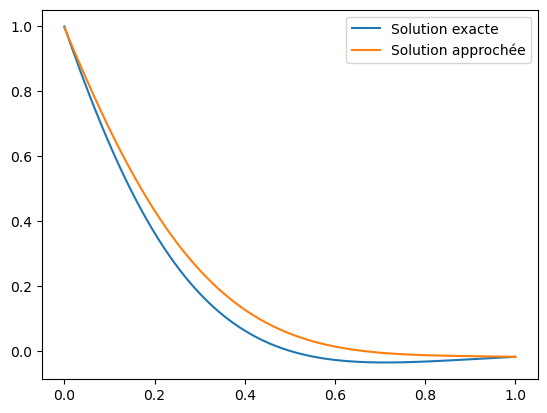

In [382]:
N = 1000
x = np.linspace(0,1,N)
ord1 = u(x)
ord2 = linear_system(N,f,b,c,alpha,beta)
plt.plot(x,ord1,label="Solution exacte")
plt.plot(x,ord2,label="Solution approchée")
plt.legend()
plt.show()

__Matrice creuse__ : 

In [426]:
def matrix_sparse_and_vector(N, f, b, c, alpha, beta):
    h = 1 / (N + 1)

    main_diag = (2 / (h ** 2)) * np.ones(N)
    off_diag = (-1 / (h ** 2)) * np.ones(N - 1)
    
    # Construction de la matrice A en utilisant csr_matrix
    data = np.concatenate([main_diag, off_diag, off_diag])
    
    # Indices pour la diagonale principale
    rows_main = np.arange(N)
    cols_main = np.arange(N)
    
    # Indices pour la diagonale supérieure
    rows_upper = np.arange(N - 1)
    cols_upper = np.arange(1, N)
    
    # Indices pour la diagonale inférieure
    rows_lower = np.arange(1, N)
    cols_lower = np.arange(N - 1)
    
    # Concaténation des indices
    rows = np.concatenate([rows_main, rows_upper, rows_lower])
    cols = np.concatenate([cols_main, cols_upper, cols_lower])

    A = csr_matrix((data, (rows, cols)), shape=(N, N)).toarray()
    
    # Deuxième et troisième matrice
    B_data = np.zeros(2 * (N - 1))
    B_rows = np.concatenate([np.arange(N - 1), np.arange(1, N)])
    B_cols = np.concatenate([np.arange(1, N), np.arange(N - 1)])
    B_data[:N - 1] = np.array([b(i * h) / (2 * h) for i in range(N - 1)])
    B_data[N - 1:] = -np.array([b(i * h) / (2 * h) for i in range(N - 1)])
    
    B = csr_matrix((B_data, (B_rows, B_cols)), shape=(N, N)).toarray()
    
    C_data = np.zeros(N)
    C_rows = np.arange(N)
    C_cols = np.arange(N)
    C_data = np.array([c(i * h) for i in range(N)])
    
    C = csr_matrix((C_data, (C_rows, C_cols)), shape=(N, N)).toarray()

    F = np.zeros(N)
    
    for i in range(N):
        xi = i * h
        F[i] = f(xi)
    
    F[0] += alpha / (h ** 2)
    F[N - 1] += beta / (h ** 2)
    
    matrix = A + B + C
    
    return matrix, F

In [428]:
def linear_system_sparse(N,f,b,c,alpha,beta):
    A,F = matrix_sparse_and_vector(N,f,b,c,alpha,beta)
    return np.linalg.solve(A,F)

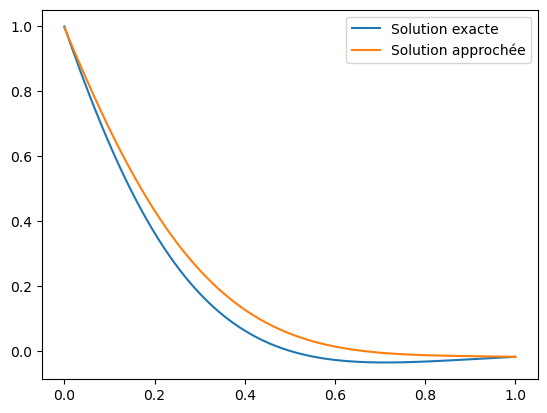

In [430]:
N = 1000
x = np.linspace(0,1,N)
ord1 = u(x)
ord2 = linear_system_sparse(N,f,b,c,alpha,beta)
plt.plot(x,ord1,label="Solution exacte")
plt.plot(x,ord2,label="Solution approchée")
plt.legend()
plt.show()